In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from keras.utils import np_utils
from keras.models import Sequential
from keras.models import Model
from keras.layers import Input
from keras.layers import Dense, Input
from keras.layers import Dropout
from keras.layers import concatenate
from keras.layers import Reshape
from keras.layers import Flatten
from keras.layers import LSTM
from keras.layers.convolutional import Convolution2D
from keras.layers.convolutional import MaxPooling2D
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from keras import backend as K
import pandas as pd
import glob
import os
import tensorflow as tf
import sklearn

import itertools
from keras.utils.np_utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.optimizers import Adam
from keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

from sklearn.metrics import confusion_matrix
import itertools

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.layers import BatchNormalization

In [ ]:
data = pd.read_csv('/content/labelled_final.csv',header=None)

In [ ]:
data=data.to_numpy()

In [ ]:
X = data[:, :52]

In [ ]:
X=pd.DataFrame(X)
X.head()

,0,1,2,3,4,5,6,7,8,9,...,42,43,44,45,46,47,48,49,50,51
0,26.0,25.0,24.2,27.7,25.2,25.9,25.5,22.8,23.3,25.8,...,19.0,17.3,14.3,17.5,18.4,16.3,14.6,17.5,15.3,16.6
1,24.1,25.7,25.2,22.0,21.4,21.4,21.0,22.0,19.6,19.0,...,17.5,16.2,18.0,17.5,19.2,17.1,14.9,18.8,14.3,14.8
2,24.2,28.3,24.8,27.0,25.6,25.5,25.8,23.9,25.6,22.8,...,17.1,19.0,16.5,18.7,18.7,15.2,16.5,17.7,16.5,15.1
3,24.2,24.4,32.8,32.5,23.4,25.5,28.3,24.2,29.2,24.8,...,22.5,19.3,19.6,20.4,17.3,18.4,17.3,18.1,18.4,16.5
4,22.1,28.5,26.6,30.8,25.3,26.5,25.1,25.2,26.7,19.2,...,21.4,21.3,19.8,18.6,19.8,17.0,18.4,21.9,16.6,17.2


In [ ]:
X.shape

(661, 52)

In [ ]:
y = data[:,52:]
y=pd.DataFrame(y)

In [ ]:
print(pd.unique(y[0]))

[0. 1. 2. 3. 4. 5. 6.]


In [ ]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder()
encoder.fit(y)
y = encoder.transform(y)

In [ ]:
print(y)

[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25,stratify=y,random_state=99)

In [ ]:
X_train = X_train.astype( 'float32' )
X_val = X_val.astype( 'float32')

In [ ]:
X_train = X_train /51.0
X_val = X_val / 51.0

In [ ]:
print("X_train shape before reshape:", X_train.shape)
print("X_test shape before reshape:", X_val.shape)

X_train shape before reshape: (495, 52)
X_test shape before reshape: (166, 52)


In [ ]:
X_train_cnn = X_train.values.reshape(-1,13,4,1)
X_val_cnn = X_val.values.reshape(-1,13,4,1)

In [ ]:
print(X_train_cnn.shape)
print(X_val_cnn.shape)

(495, 13, 4, 1)
(166, 13, 4, 1)


In [ ]:
X_train_lstm = np.squeeze(X_train_cnn, axis=3)
X_train_lstm = np.transpose(X_train_lstm, (0, 1, 2))
X_val_lstm = np.squeeze(X_val_cnn, axis=3)
X_val_lstm = np.transpose(X_val_lstm, (0, 1, 2))

In [ ]:
print(X_train_lstm.shape)
print(X_val_lstm.shape)

(495, 13, 4)
(166, 13, 4)


In [ ]:
y_val

array([[2.],
       [2.],
       [4.],
       [4.],
       [1.],
       [5.],
       [0.],
       [0.],
       [3.],
       [4.],
       [6.],
       [0.],
       [2.],
       [2.],
       [1.],
       [0.],
       [2.],
       [2.],
       [3.],
       [2.],
       [2.],
       [4.],
       [4.],
       [2.],
       [4.],
       [5.],
       [6.],
       [3.],
       [5.],
       [6.],
       [5.],
       [1.],
       [4.],
       [3.],
       [2.],
       [1.],
       [4.],
       [1.],
       [1.],
       [5.],
       [1.],
       [6.],
       [4.],
       [4.],
       [5.],
       [6.],
       [2.],
       [3.],
       [5.],
       [0.],
       [0.],
       [0.],
       [1.],
       [6.],
       [6.],
       [5.],
       [1.],
       [4.],
       [3.],
       [4.],
       [3.],
       [3.],
       [6.],
       [6.],
       [4.],
       [1.],
       [1.],
       [2.],
       [2.],
       [5.],
       [6.],
       [0.],
       [6.],
       [0.],
       [0.],
       [4.],
       [3.],

In [ ]:
y_val.shape

(166, 1)

In [ ]:
model = Sequential()
model.add(Conv2D(filters = 64, kernel_size = (3,3),
                 activation ='relu', input_shape = (13,4,1)))
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2), padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu',padding='same'))
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2), padding='same'))
# model.add(Convolution2D(15, 3, 3, activation= 'relu' ))
# model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))
model.add(Flatten())

# model.add(LSTM(units=128, input_shape=(1,13,4)))
# model.add(Dense(256, activation= 'relu' ))
model.add(Dense(50, activation= 'relu' ))
# model.add(Dense(7, activation= 'softmax' ))

lstm_model = Sequential()
lstm_model.add(LSTM(units=128, input_shape=(13,4)))
# lstm_model.add(Dense(100, activation= 'relu' ))
lstm_model.add(Dense(50, activation= 'relu' ))

combined = concatenate([model.output, lstm_model.output])
# combined = Dense(units=512, activation='relu')(combined)
combined = Dense(units=50, activation='selu')(combined)
# combined = Dense(units=50, activation='relu')(combined)
# output_layer = Dense(units=100, activation='relu')(combined)
# output_layer = Dense(units=50, activation='relu')(combined)
output_layer = Dense(1, activation='selu')(combined)

f_model = Model(inputs=[model.input, lstm_model.input], outputs=output_layer)


In [ ]:
from keras.callbacks import EarlyStopping,ReduceLROnPlateau

#early_stopping = EarlyStopping(monitor='val_loss', patience=10)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=5, min_lr=0.0001)

In [ ]:
from keras import optimizers
f_model.compile(loss='mae', optimizer='adam', metrics=['mae'])

f_model.summary()

Model: "model_12"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 conv2d_50_input (InputLayer)   [(None, 13, 4, 1)]   0           []                               
                                                                                                  
 conv2d_50 (Conv2D)             (None, 11, 2, 64)    640         ['conv2d_50_input[0][0]']        
                                                                                                  
 conv2d_51 (Conv2D)             (None, 11, 2, 64)    36928       ['conv2d_50[0][0]']              
                                                                                                  
 max_pooling2d_25 (MaxPooling2D  (None, 6, 1, 64)    0           ['conv2d_51[0][0]']              
 )                                                                                         

In [ ]:
history = f_model.fit([X_train_cnn,X_train_lstm], y_train, epochs =100,validation_data =([X_val_cnn,X_val_lstm],y_val),callbacks=[reduce_lr])
# history = model.fit(X_train_cnn, y_train, epochs = 100,validation_data =(X_val_cnn,y_val))

Epoch 1/100
16/16 [==============================] - 6s 136ms/step - loss: 1.7529 - mae: 1.7529 - val_loss: 2.5448 - val_mae: 2.5448 - lr: 0.0010
Epoch 2/100
16/16 [==============================] - 1s 77ms/step - loss: 1.1629 - mae: 1.1629 - val_loss: 2.4503 - val_mae: 2.4503 - lr: 0.0010
Epoch 3/100
16/16 [==============================] - 1s 46ms/step - loss: 1.0180 - mae: 1.0180 - val_loss: 2.5364 - val_mae: 2.5364 - lr: 0.0010
Epoch 4/100
16/16 [==============================] - 1s 54ms/step - loss: 1.0245 - mae: 1.0245 - val_loss: 2.4355 - val_mae: 2.4355 - lr: 0.0010
Epoch 5/100
16/16 [==============================] - 1s 50ms/step - loss: 0.8874 - mae: 0.8874 - val_loss: 2.3257 - val_mae: 2.3257 - lr: 0.0010
Epoch 6/100
16/16 [==============================] - 1s 51ms/step - loss: 0.8553 - mae: 0.8553 - val_loss: 2.3728 - val_mae: 2.3728 - lr: 0.0010
Epoch 7/100
16/16 [==============================] - 1s 49ms/step - loss: 0.8354 - mae: 0.8354 - val_loss: 2.2760 - val_mae: 2.27

In [ ]:
f_model.evaluate([X_val_cnn,X_val_lstm], y_val)

6/6 [==============================] - 0s 18ms/step - loss: 0.5068 - mae: 0.5068


[0.5068035125732422, 0.5068035125732422]

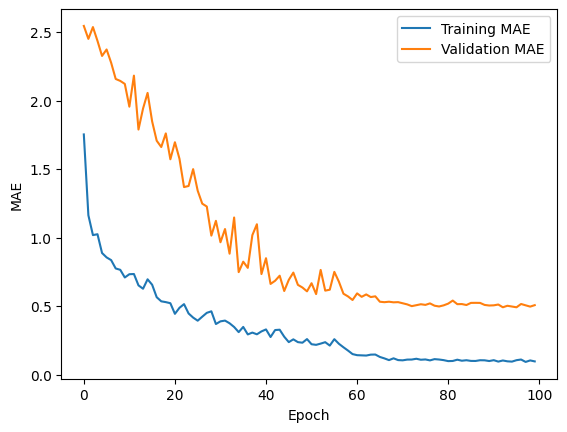

In [ ]:
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.show()